# Revenant Conduit (Harakim)

Revenant Conduit is a toggled self buff. While it is open, the caster's Ghost Companion skill
counts as 30–150% higher when companions are statted. Existing companions are re-statted
immediately. Every point of post-mitigation damage a companion deals also heals the (player)
owner for 10–50% of it. The conduit drains 1 endurance per second for each live companion and
closes when endurance runs out, when it expires after 360 s, or when the caster recasts it.

**Rebalanced.** The boost used to climb in +30% steps every 10 skill points and saturated at
skill 50. It now rises linearly, `30 + 6p/5`, and reaches +150% at skill 100
(`revenant_conduit_boost_pct`), the same shape as Spectral Pact. The heal is still one third of the
boost, so it spreads over the same range. The drain was a flat 1 endurance per second. It now
costs 1 per second per live companion (`owned_live_companion_count`, minimum 1), so a second
companion from Kindred Spirit no longer doubles the lifesteal for free. The "before" curves below
show the old behaviour.

| | |
|---|---|
| Class | Harakim |
| Target | Self (affects owned ghost companions) |
| Cost | 17 mana (not divided by 3 for Harakim); needs at least 25 endurance but does not spend it |
| Upkeep | 1 endurance per second per live companion (at least 1) while open |
| Cooldown | none; recasting while open closes it (toggle) |
| Landing roll | none |
| Duration | 360 s, or until endurance reaches 0, the caster recasts it, or no companion is left |
| Effect | `boost = clamp(30 + ⌊6p/5⌋, 30, 150)` %; companions are statted from `ghost·(100+boost)/100`; owner healed `clamp(⌊boost/3⌋, 0, 50)` % of companion damage |
| Source | `server/src/driver/skill/companion.rs::skill_revenant_conduit`, `revenant_conduit_boost_pct`, `recompute_companion_stats`; drain and heal in `server/src/state/stats.rs` (`apply_revenant_conduit_heal`) |

---

# Formula

With $p$ the modified Revenant Conduit skill, $g$ the modified Ghost Companion skill and $n$ the
number of live companions:

$$
\text{boost} = \operatorname{clamp}\!\left(30 + \lfloor 6p/5 \rfloor,\ 30,\ 150\right)\%
\qquad
\text{heal} = \operatorname{clamp}\!\left(\lfloor \text{boost}/3 \rfloor,\ 0,\ 50\right)\%
\qquad
\text{drain} = \max(1, n)\ \text{endurance/s}
$$

$$
g' = \left\lfloor \frac{g\,(100 + \text{boost})}{100} \right\rfloor
\qquad
\text{base} = \text{race}\!\left(\left\lfloor \tfrac{4g'}{11} \right\rfloor\right)
\qquad
\text{attribute} = \max\!\left(10,\ \min\!\left(\text{cap},\ \left\lfloor \tfrac{3\,\text{base}}{\text{attrib}[3]} \right\rfloor\right)\right)
\qquad
\text{HP} = \max(50,\ \min(\text{cap},\ 5\,\text{base}))
$$

Skills follow the attribute rule with the template's `skill[n][3]` divisor. The template caps
(`attrib[n][2]`, `skill[n][2]`, `hp[2]`) come from the `CT_COMPANION` template in the world
snapshot, so this notebook models the **uncapped** values with divisor 1, as the Rust test does.

| Quantity | Breakpoint |
|---|---|
| Boost and heal floor | +30% and 10% at $p = 0$ |
| Boost and heal ceiling | +150% and 50% from $p \ge 100$ (before: from $p \ge 50$) |
| Slope | +1.2% boost / +0.4% heal per skill point (before: +30% / +10% per 10 points) |
| Upkeep | 17 mana, plus 360 endurance per companion for a full 360 s |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
MANA_COST = 17
END_GATE = 25
DURATION_S = 360
GHOST_SWEEP = (50, 80, 105, 120)

# Model

In [2]:
def boost_pct(p):
    return mm.clamp(30 + mm.idiv(np.asarray(p) * 6, 5), 30, 150)


def heal_pct(p):
    return mm.clamp(mm.idiv(boost_pct(p), 3), 0, 50)


def drain_per_s(companions):
    return np.maximum(1, np.asarray(companions))


def open_seconds(endurance, companions):
    """Seconds the conduit stays open on a full `endurance` pool (capped by the 360 s duration)."""
    return np.minimum(DURATION_S, mm.idiv(endurance, drain_per_s(companions)))


# Before the rebalance: +30% per 10 skill points, saturating at skill 50, and a flat 1 end/s drain.
def old_boost_pct(p):
    return mm.clamp(mm.idiv(p, 10) * 10 * 3, 30, 150)


def old_heal_pct(p):
    return mm.clamp(mm.idiv(old_boost_pct(p), 3), 0, 50)


def companion_base(ghost, boost=0, race="Harakim"):
    eff = np.asarray(ghost) * (100 + np.asarray(boost)) // 100
    return mm.spell_race_mod(mm.idiv(eff * 4, 11), race)


def companion_attrib(base, divisor=1):
    return np.maximum(10, mm.idiv(np.asarray(base) * 3, divisor))


def companion_hp(base):
    return np.maximum(50, np.asarray(base) * 5)


def heal_hp(companion_damage_hp, p):
    """HP the owner regains for `companion_damage_hp` HP of post-mitigation companion damage."""
    return np.asarray(companion_damage_hp) * heal_pct(p) / 100

# Validation

- `revenant_conduit_boosts_existing_companions_and_toggles_off`: skill 20 → boost 54, mana
  50,000 → 33,000, endurance unchanged; recasting removes the item.
- `revenant_conduit_boost_is_clamped`: skill 0 → 30, skill 200 → 150.
- `revenant_conduit_boost_scales_linearly_to_skill_100`: 0 → 30, 5 → 36, 50 → 90, 99 → 148,
  100 → 150, 105 → 150.
- `revenant_conduit_requires_endurance`: 24,000 endurance is refused.
- `restat_owned_companions_scales_stats_from_ghost_skill` (Ghost 110): base 40 → attributes 120,
  HP and endurance 200, mana 0. With the conduit at skill 20 (+54%): 169 → base 61 → attributes 183.
- `revenant_conduit_heals_owner_by_scaled_damage_percentage`: boost 30 heals 2,000 of 20,000;
  boost 150 heals 10,000.
- `revenant_conduit_drain_scales_with_companion_count`: 0 and 1 companions drain the same; a
  second companion drains 1,000 (1 endurance) more per second.

In [3]:
assert boost_pct(20) == 54 and boost_pct(0) == 30 and boost_pct(200) == 150
assert [int(boost_pct(p)) for p in (5, 50, 99, 100, 105)] == [36, 90, 148, 150, 150]
assert 50_000 - MANA_COST * 1000 == 33_000 and 24_000 < END_GATE * 1000
assert companion_base(110) == 40 and companion_attrib(40) == 120 and companion_hp(40) == 200
assert companion_base(110, 54) == 61 and companion_attrib(61) == 183
assert mm.idiv(20_000 * mm.clamp(mm.idiv(30, 3), 0, 50), 100) == 2_000
assert mm.idiv(20_000 * mm.clamp(mm.idiv(150, 3), 0, 50), 100) == 10_000
assert drain_per_s(0) == drain_per_s(1) == 1 and drain_per_s(2) == 2
assert heal_pct(99) == 49 and heal_pct(100) == 50
assert old_boost_pct(20) == 60 and old_boost_pct(50) == 150 and old_heal_pct(50) == 50
print("Revenant Conduit model OK")

Revenant Conduit model OK


# Plots

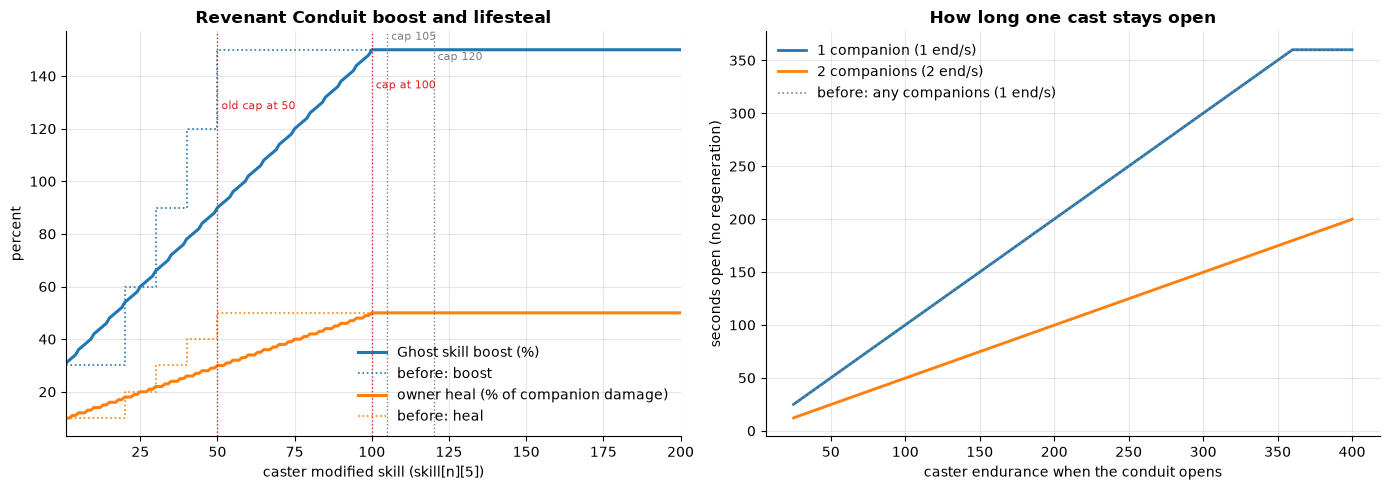

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
line, = ax.plot(P, boost_pct(P), lw=2.2, label="Ghost skill boost (%)")
ax.step(P, old_boost_pct(P), where="post", color=line.get_color(), lw=1.2, ls=":",
        label="before: boost")
line, = ax.plot(P, heal_pct(P), lw=2.2, label="owner heal (% of companion damage)")
ax.step(P, old_heal_pct(P), where="post", color=line.get_color(), lw=1.2, ls=":",
        label="before: heal")
mm.skill_axis(ax, "percent", "Revenant Conduit boost and lifesteal")
mm.mark_caps(ax, extra=[(100, "cap at 100"), (50, "old cap at 50")])
ax.legend()

ax = axes[1]
END = np.arange(25, 401)
for n in (1, 2):
    ax.plot(END, open_seconds(END, n), label=f"{n} companion{'s' if n > 1 else ''} ({n} end/s)")
ax.plot(END, np.minimum(DURATION_S, END), color="grey", lw=1.2, ls=":", label="before: any companions (1 end/s)")
ax.set_xlabel("caster endurance when the conduit opens")
ax.set_ylabel("seconds open (no regeneration)")
ax.set_title("How long one cast stays open")
ax.legend()
plt.tight_layout()

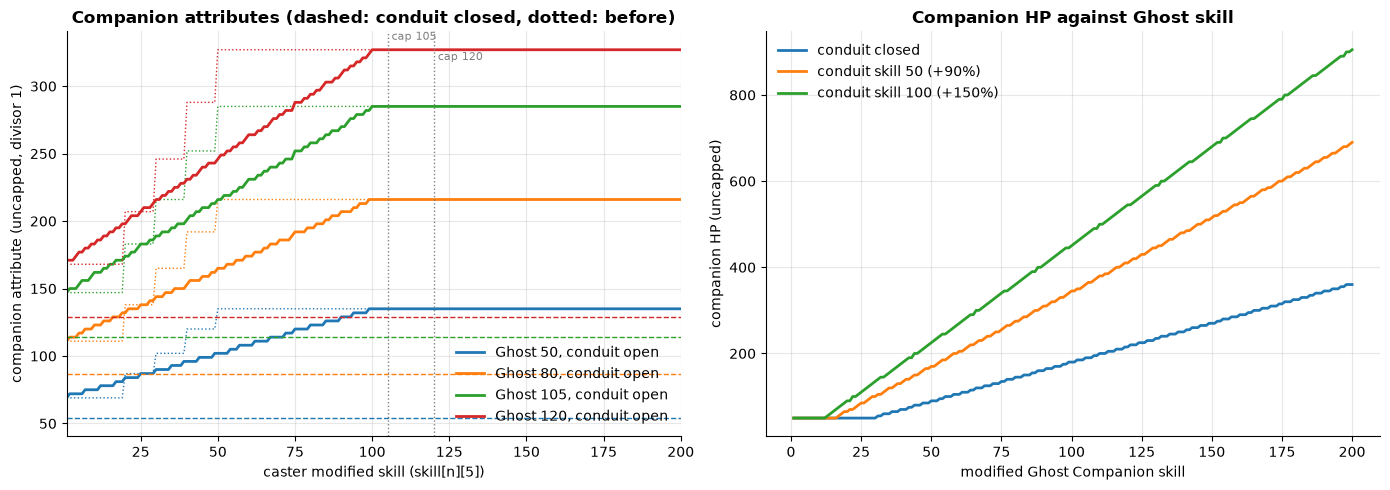

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for g in GHOST_SWEEP:
    line, = ax.plot(P, companion_attrib(companion_base(g, boost_pct(P))), label=f"Ghost {g}, conduit open")
    ax.plot(P, companion_attrib(companion_base(g, old_boost_pct(P))), color=line.get_color(), lw=1, ls=":")
    ax.axhline(companion_attrib(companion_base(g)), color=line.get_color(), ls="--", lw=1)
mm.skill_axis(ax, "companion attribute (uncapped, divisor 1)",
              "Companion attributes (dashed: conduit closed, dotted: before)")
mm.mark_caps(ax)
ax.legend()

ax = axes[1]
G = np.arange(1, 201)
for p in (0, 50, 100):
    label = "conduit closed" if p == 0 else f"conduit skill {p} (+{int(boost_pct(p))}%)"
    b = companion_base(G) if p == 0 else companion_base(G, boost_pct(p))
    ax.plot(G, companion_hp(b), label=label)
ax.set_xlabel("modified Ghost Companion skill")
ax.set_ylabel("companion HP (uncapped)")
ax.set_title("Companion HP against Ghost skill")
ax.legend()
plt.tight_layout()

# Observations

- **Saturates at skill 100 (was 50).** The boost now climbs smoothly by 1.2% per skill point
  (0.4% heal) from +30% / 10% at skill 0 to +150% / 50% at skill 100, just under the 105 raise cap.
  Before, it moved in +30% steps every 10 points and capped at skill 50, so the second half of the
  trained range did nothing. Low-skill casters lose a little (+54% instead of +60% at skill 20,
  +90% instead of +150% at 50); the old ceiling now needs a fully trained skill.
- **×2.5 companion at the top.** With Ghost 105 the companion's base goes from 38 to 72 at skill 50
  (attributes 114 → 216, HP 190 → 360) and to 95 at skill 100 (285 attributes, 475 HP, uncapped).
  With Ghost 120 it is 129 → 246 → 327 attributes and 215 → 410 → 545 HP. The template caps
  (`attrib[n][2]`, `skill[n][2]`, `hp[2]`) may cut this down. They live in the world snapshot,
  so check them before tuning: if they sit near the closed-conduit values, most of the boost is
  wasted, and the lifesteal is the only part that matters.
- **Up to 50% lifesteal on someone else's damage.** Every HP a companion removes after armor heals
  the owner for up to half of it, with no cap other than the owner's max HP. Only player owners
  are healed.
- **A second companion now pays its own way.** The drain is 1 endurance per second per live
  companion, counted on every tick, so with Kindred Spirit's second ghost the conduit costs 2/s
  and a full 360 s needs 720 endurance instead of 360. With no companion it still drains 1/s. The
  lifesteal per companion is unchanged, so two companions still heal twice as much, but at twice
  the upkeep.
- **Cheap to open.** 17 mana opens it for up to 360 s. The 25-endurance gate is checked but never
  spent. The talent text ("at the cost of mana and a steady endurance drain") matches this.
- **Toggling is free in both directions.** Closing it costs nothing and needs no endurance, and
  re-opening costs 17 mana with no cooldown. Companions are re-statted on every toggle, so the
  boost applies to ghosts that are already summoned.
- **It closes itself when the pack is gone.** `clear_companion_dependent_buffs` removes it when the
  owner has no living companion, so a dead ghost forces a resummon (45 mana) and a recast.
- **Not changed.** The heal ceiling stays at 50% (`boost/3`). If two-companion lifesteal is still
  too strong after the drain change, the next step is decoupling the heal from the boost, for
  example `heal = clamp(p/4, 5, 30)`, stored on the marker alongside the boost.